# Evento Evaluativo 4 · Machine Learning · Intención de compra en e-commerce
## Notebook 01 — Descripción del problema y análisis exploratorio (EDA)

**Grupo 3 · Análisis de Datos · ITM 2026-2 · Docente: Daniel Alexis Nieto Mora**
Integrantes: Santiago Betancur (@Xantyagoh) · Diego Alzate (@DiegoA1123) · Carlos Mendez (@carmarisx) · Sebastian Cadavid (@Exmen9) · Daniel Martinez (@danielmmnez)

**Qué hace este notebook:** describe el problema, presenta el dataset, audita su calidad y lo explora (univariado y bivariado) para decidir el preprocesamiento (notebook 02) y los modelos (notebooks 03 y 04).

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

## 1. Descripción del problema

Un comercio electrónico registra miles de **sesiones de navegación**: cuántas páginas vio cada visitante, cuánto tiempo estuvo, desde dónde llegó y si al final **compró o no**. La mayoría de las sesiones **no termina en compra**, así que el negocio necesita dos cosas distintas:

| Componente | Pregunta de negocio | Tipo de aprendizaje |
|---|---|---|
| **Supervisado** | Dada una sesión, ¿**terminará en compra**? (variable objetivo `Revenue`) | Clasificación binaria con desbalance |
| **No supervisado** | ¿Qué **tipos de visitantes** hay según su forma de navegar? (sin mirar `Revenue`) | Agrupamiento (segmentación) |

**Por qué importa:** predecir la intención de compra permite actuar mientras el visitante aún navega (un cupón, un chat de ayuda); segmentar permite diseñar estrategias distintas para visitantes exploratorios, comprometidos o que rebotan.

### Preguntas que queremos responder
1. ¿Qué tan desbalanceada está la compra y cómo afecta la elección de métricas?
2. ¿Qué características de la sesión se relacionan con comprar?
3. ¿Qué tan bien se puede predecir la compra y **cuánto depende de una sola variable** (`PageValues`)?
4. ¿Existen segmentos de visitantes con comportamientos claramente distintos?
5. ¿Los segmentos descubiertos **sin etiquetas** coinciden con quienes compran?
6. ¿Qué enfoque recomendaríamos para una aplicación real?

## 2. El dataset

**Dataset:** *Online Shoppers Purchasing Intention Dataset* — UCI Machine Learning Repository (id 468).
**Cita:** Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q · Licencia CC BY 4.0.
**Artículo asociado:** Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
**Contenido:** 12.330 sesiones, 17 variables + `Revenue`. Cada sesión pertenece a **un usuario distinto** dentro de un periodo de un año (para evitar sesgos por campaña, fecha especial o perfil de usuario). Sin valores faltantes.

In [2]:
df = pd.read_csv(DATOS)
print('Sesiones:', f'{df.shape[0]:,}', '| Variables:', df.shape[1])
df.head()

Sesiones: 12,330 | Variables: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

### Diccionario de datos

| Variable | Tipo | Significado |
|---|---|---|
| `Administrative`, `Administrative_Duration` | numérica | Nº de páginas administrativas (cuenta, perfil) visitadas y tiempo total en ellas (segundos) |
| `Informational`, `Informational_Duration` | numérica | Ídem para páginas informativas (contacto, ayuda, la empresa) |
| `ProductRelated`, `ProductRelated_Duration` | numérica | Ídem para páginas de **productos** |
| `BounceRates` | numérica (0–1) | % de visitas que entran a la página y se van sin hacer nada más (Google Analytics) |
| `ExitRates` | numérica (0–1) | % de vistas de la página que fueron la **última** de la sesión (Google Analytics) |
| `PageValues` | numérica | Valor promedio de las páginas visitadas **antes de completar una transacción** (Google Analytics) |
| `SpecialDay` | numérica (0–1) | Cercanía de la visita a una fecha especial (San Valentín, Día de la Madre…); 1 = máxima cercanía |
| `Month` | categórica | Mes de la visita (10 meses; no hay enero ni abril) |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | categórica (códigos) | Sistema operativo, navegador, región y tipo de tráfico, codificados como números **sin orden** |
| `VisitorType` | categórica | `Returning_Visitor`, `New_Visitor` u `Other` |
| `Weekend` | binaria | ¿La visita fue en fin de semana? |
| **`Revenue`** | **binaria (objetivo)** | **¿La sesión terminó en compra?** |

**Unidad de observación:** una sesión de navegación.

In [4]:
ficha = pd.Series({
    'Sesiones': f'{len(df):,}',
    'Variables predictoras': df.shape[1] - 1,
    'Numericas': 10, 'Categoricas (codigos o texto)': 6, 'Binarias': 1,
    'Sesiones que terminan en compra': f'{df["Revenue"].sum():,} ({df["Revenue"].mean():.1%})',
    'Meses presentes': df['Month'].nunique(),
}, name='valor').to_frame()
ficha

,valor
Sesiones,"12,330"
Variables predictoras,17
Numericas,10
Categoricas (codigos o texto),6
Binarias,1
Sesiones que terminan en compra,"1,908 (15.5%)"
Meses presentes,10


## 3. Calidad de los datos

Antes de explorar se revisa si hay faltantes, duplicados, valores imposibles y variables problemáticas. **Cada hallazgo condiciona una decisión de preprocesamiento.**

In [5]:
calidad = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'valores_unicos': df.nunique(),
    'min': df.select_dtypes('number').min(),
    'max': df.select_dtypes('number').max(),
})
calidad

,dtype,nulos,valores_unicos,min,max
Administrative,int64,0,27,0.000,27.000
Administrative_Duration,float64,0,3335,0.000,"3,398.750"
BounceRates,float64,0,1872,0.000,0.200
Browser,int64,0,13,1.000,13.000
ExitRates,float64,0,4777,0.000,0.200
Informational,int64,0,17,0.000,24.000
Informational_Duration,float64,0,1258,0.000,"2,549.375"
Month,str,0,10,NaN,NaN
OperatingSystems,int64,0,8,1.000,8.000
PageValues,float64,0,2704,0.000,361.764


In [6]:
duplicadas = int(df.duplicated().sum())
negativos = int((df.select_dtypes('number') < 0).sum().sum())
tasa_con = df['Revenue'].mean()
tasa_sin = df.drop_duplicates()['Revenue'].mean()

print(f'Valores faltantes totales : {int(df.isna().sum().sum())}')
print(f'Valores numericos negativos: {negativos}')
print(f'Sesiones duplicadas exactas: {duplicadas} ({duplicadas / len(df):.2%})')
print(f'Tasa de compra con duplicados: {tasa_con:.2%} | sin duplicados: {tasa_sin:.2%}')

Valores faltantes totales : 0
Valores numericos negativos: 0
Sesiones duplicadas exactas: 125 (1.01%)
Tasa de compra con duplicados: 15.47% | sin duplicados: 15.63%


In [7]:
# Coherencia interna: si no se visitan paginas de un tipo, su duracion deberia ser 0
for pag, dur in [('Administrative', 'Administrative_Duration'), ('Informational', 'Informational_Duration'),
                 ('ProductRelated', 'ProductRelated_Duration')]:
    sin_paginas = df[pag] == 0
    print(f'{pag:<15} sin paginas: {sin_paginas.sum():>6,} sesiones | con duracion > 0 pese a 0 paginas: {(sin_paginas & (df[dur] > 0)).sum()}')

# Cardinalidad de las variables nominales
card = df[['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']].nunique().rename('categorias').to_frame()
card

Administrative  sin paginas:  5,768 sesiones | con duracion > 0 pese a 0 paginas: 0
Informational   sin paginas:  9,699 sesiones | con duracion > 0 pese a 0 paginas: 0
ProductRelated  sin paginas:     38 sesiones | con duracion > 0 pese a 0 paginas: 0


,categorias
Month,10
VisitorType,3
OperatingSystems,8
Browser,13
Region,9
TrafficType,20


**Lectura de la auditoría y decisión asociada**

| Hallazgo | Magnitud | Decisión |
|---|---|---|
| Valores faltantes | **0** | No hace falta imputar |
| Valores negativos o inconsistentes | **0** (ninguna sesión tiene duración > 0 con 0 páginas) | Datos coherentes |
| Sesiones **duplicadas exactas** | **125** (1,0 %); todas son sesiones *sin compra* (la tasa sube de 15,47 % a 15,63 % al quitarlas) | **Eliminarlas antes de dividir** en train/test: si un duplicado cae en cada lado, el modelo "ve" la respuesta |
| Sesiones sin páginas administrativas / informativas | 46,8 % / 78,7 % | Esperable: no todos visitan esas secciones. Los muchos ceros piden transformar las variables (log) |
| Cardinalidad de las nominales | `TrafficType` 20, `Browser` 13, `Month` 10, `Region` 9, `OperatingSystems` 8 | **Ninguna es de cardinalidad realmente alta**: se puede usar one-hot (~73 columnas) |

### ⚠️ Advertencia metodológica sobre `PageValues`

Según la documentación del dataset, `PageValues` es *"el valor promedio de las páginas que el usuario visitó **antes de completar una transacción**"*. Es decir, se calcula en parte con información del **resultado** de la sesión: una sesión sin compra casi siempre tiene `PageValues = 0`.

Esto es un riesgo clásico de **fuga de información (data leakage)**: el modelo podría "predecir" la compra usando una variable que ya contiene la compra. No se descarta la variable sin evidencia; en cambio, el proyecto **medirá cuánto depende el modelo de ella** (notebook 03: modelo con y sin `PageValues`) y la **excluirá del agrupamiento** (notebook 04).

## 4. Plan de trabajo

| Notebook | Contenido |
|---|---|
| `01_problema_y_eda` | Problema, datos, calidad y EDA *(este)* |
| `02_preprocesamiento` | División train/test, pipeline sin fuga de información, selección de variables y PCA |
| `03_supervisado` | Regresión logística, Random Forest y Gradient Boosting; desbalance, umbral, importancia, ablación de `PageValues` |
| `04_no_supervisado` | K-Means, Gaussian Mixture y Aglomerativo; métricas, PCA/t-SNE, perfiles y relación con `Revenue` |
| `05_comparacion_y_conclusiones` | Respuestas a las 8 preguntas comparativas y recomendación |

## 5. EDA univariado

### 5.1 Variable objetivo y desbalance

Sesiones tras quitar duplicados: 12,205
Revenue
No compra    10297
Compra        1908

Tasa de compra: 15.63%  |  razon no-compra : compra = 5.4 : 1
Accuracy de un "modelo" que siempre dice NO COMPRA: 84.37%


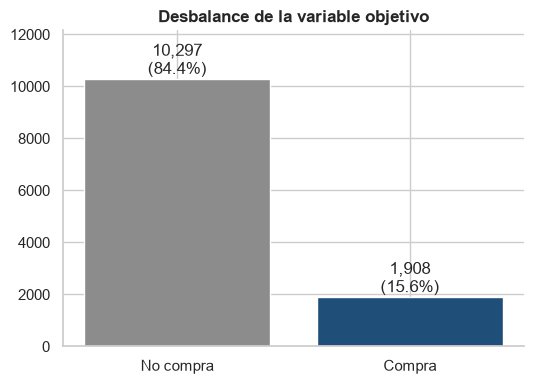

In [8]:
df = df.drop_duplicates().reset_index(drop=True)      # a partir de aqui se trabaja sin duplicados (ver seccion 3)
conteo = df['Revenue'].value_counts()
print(f'Sesiones tras quitar duplicados: {len(df):,}')
print(conteo.rename({False: 'No compra', True: 'Compra'}).to_string())
print(f'\nTasa de compra: {df["Revenue"].mean():.2%}  |  razon no-compra : compra = {conteo[False] / conteo[True]:.1f} : 1')
print(f'Accuracy de un "modelo" que siempre dice NO COMPRA: {conteo[False] / len(df):.2%}')

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(['No compra', 'Compra'], [conteo[False], conteo[True]], color=[GRIS, AZUL])
for i, v in enumerate([conteo[False], conteo[True]]):
    ax.text(i, v, f'{v:,}\n({v / len(df):.1%})', ha='center', va='bottom')
ax.set_title('Desbalance de la variable objetivo'); ax.set_ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.savefig(FIG / '01_desbalance_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

**Desbalance:** tras quitar duplicados quedan **12.205 sesiones: 10.297 sin compra y 1.908 con compra (15,6 %)**, es decir, **5,4 sesiones sin compra por cada una con compra**.

**Consecuencias para el modelado**
- El **accuracy engaña**: responder siempre "no compra" da 84,4 % sin detectar nada. Se usarán **PR-AUC, Recall, Precision y F1** (el enunciado pide F1, Recall, Precision y ROC-AUC; se añade PR-AUC por ser la más exigente con clases raras).
- La división train/test debe ser **estratificada** para conservar el 15,6 % en ambos lados.
- Se tratará el desbalance con **pesos de clase y ajuste del umbral**, no con remuestreo previo a la división (causaría fuga).

### 5.2 Variables numéricas
Las variables de conteo y duración suelen tener **muchos ceros y colas largas**. Se mide asimetría y proporción de ceros para decidir si hace falta una transformación.

In [9]:
NUM = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
       'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
resumen = df[NUM].describe(percentiles=[.5, .95]).T[['mean', 'std', '50%', '95%', 'max']]
resumen['skew'] = df[NUM].skew()
resumen['% ceros'] = (df[NUM] == 0).mean() * 100
resumen

,mean,std,50%,95%,max,skew,% ceros
Administrative,2.339,3.330,1.000,9.000,27.000,1.947,46.235
Administrative_Duration,81.646,177.492,9.000,352.208,"3,398.750",5.592,47.341
Informational,0.509,1.276,0.000,3.000,24.000,4.014,78.443
Informational_Duration,34.825,141.425,0.000,199.000,"2,549.375",7.540,80.295
ProductRelated,32.046,44.594,18.000,110.000,705.000,4.333,0.311
ProductRelated_Duration,"1,206.982","1,919.601",608.943,"4,312.956","63,973.522",7.253,5.162
BounceRates,0.020,0.045,0.003,0.149,0.200,3.162,45.211
ExitRates,0.041,0.046,0.025,0.174,0.200,2.235,0.623
PageValues,5.950,18.654,0.000,38.301,361.764,6.351,77.632
SpecialDay,0.062,0.200,0.000,0.600,1.000,3.286,89.766


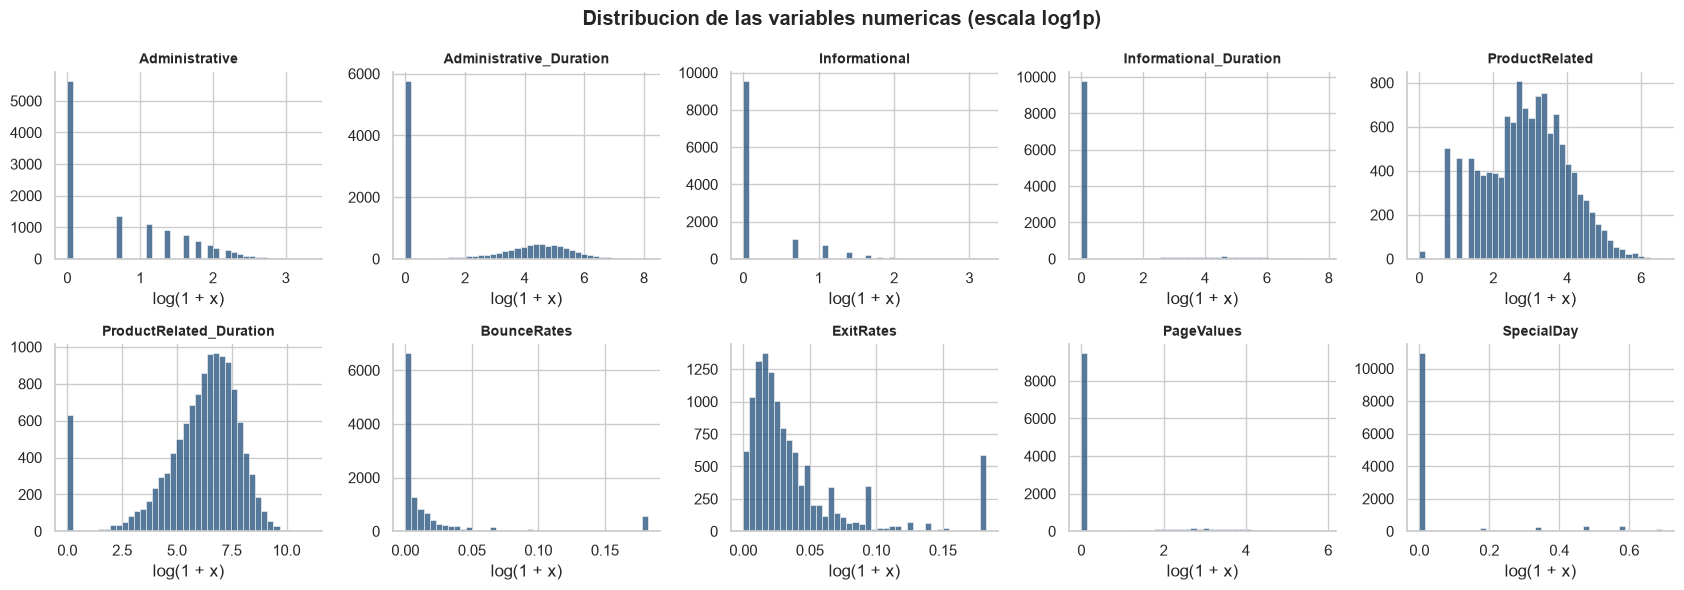

In [10]:
fig, axs = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(axs.flat, NUM):
    sns.histplot(np.log1p(df[col]), bins=40, color=AZUL, ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel('log(1 + x)'); ax.set_ylabel('')
plt.suptitle('Distribucion de las variables numericas (escala log1p)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / '01_distribuciones_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

**Lo que muestran las distribuciones**
- Todas son **muy asimétricas** (asimetría de 1,9 a 7,5) y con **muchos ceros**: `Informational` 78 % de ceros, `Informational_Duration` 80 %, `PageValues` 78 %, `SpecialDay` 90 %, `Administrative` 46 %. Casi todas las sesiones tienen páginas de producto (`ProductRelated` solo 0,3 % de ceros).
- La sesión típica es corta: **mediana de 18 páginas de producto y ~10 minutos** (609 s) en ellas; el promedio (1.207 s) es el doble por unas pocas sesiones larguísimas (máximo de ~17,8 horas).
- Esto justifica aplicar **`log(1 + x)`** (mantiene el cero y reduce la cola) y estandarizar antes de modelos lineales y de agrupamiento. Los atípicos son sesiones reales (visitantes muy activos), **no se eliminan**.

### 5.3 Variables categóricas

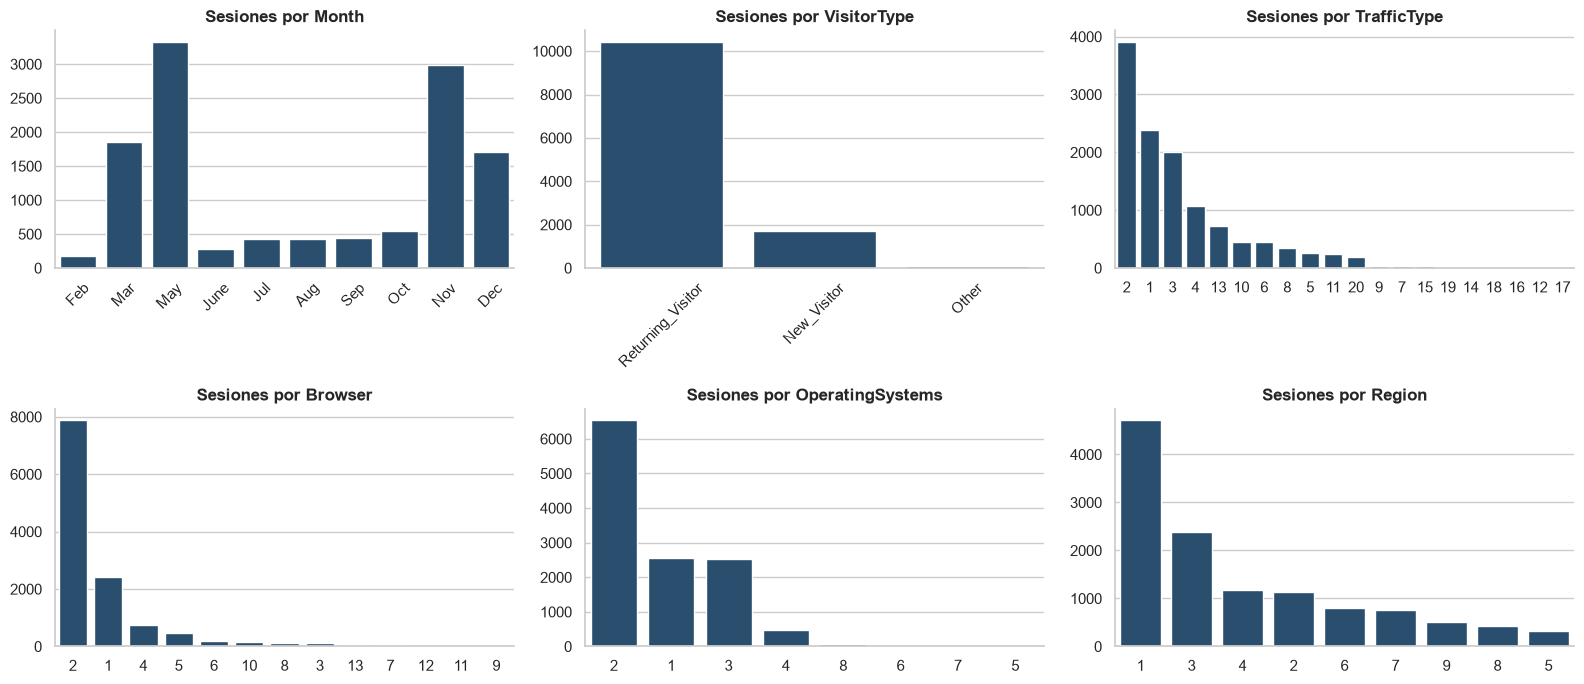

Weekend: {False: 0.766, True: 0.234}


In [11]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7))
orden_mes = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for ax, col in zip(axs.flat, ['Month', 'VisitorType', 'TrafficType', 'Browser', 'OperatingSystems', 'Region']):
    orden = orden_mes if col == 'Month' else df[col].value_counts().index
    sns.countplot(data=df, x=col, order=orden, color=AZUL, ax=ax)
    ax.set_title(f'Sesiones por {col}'); ax.set_xlabel(''); ax.set_ylabel('')
    if col in ('Month', 'VisitorType'):
        ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(FIG / '01_categoricas.png', dpi=150, bbox_inches='tight')
plt.show()
print('Weekend:', df['Weekend'].value_counts(normalize=True).round(3).to_dict())

**Lo que muestran las categóricas**
- **85,5 % de las sesiones son de visitantes recurrentes** y 13,9 % de nuevos; la categoría `Other` (0,7 %) es demasiado pequeña para sacar conclusiones.
- La actividad se concentra en pocos meses: **mayo (3.329) y noviembre (2.982)** suman más de la mitad de las sesiones; febrero tiene solo 181. El dataset **no tiene enero ni abril**.
- `TrafficType` 2 aporta el 32 % del tráfico y `Browser` 2 el 65 %: pocas categorías dominan y muchas son raras. Al codificarlas con one-hot, las categorías nuevas en test se ignoran de forma segura (`handle_unknown='ignore'`).
- El 23,4 % de las sesiones ocurre en fin de semana.

## 6. EDA bivariado: ¿qué se relaciona con comprar?

### 6.1 Tasa de compra por categoría
La **tasa de compra** (proporción de sesiones con `Revenue = True`) por categoría muestra qué segmentos compran más. Se marca la tasa global como referencia y se muestra el tamaño de cada grupo para no interpretar categorías con pocas sesiones.

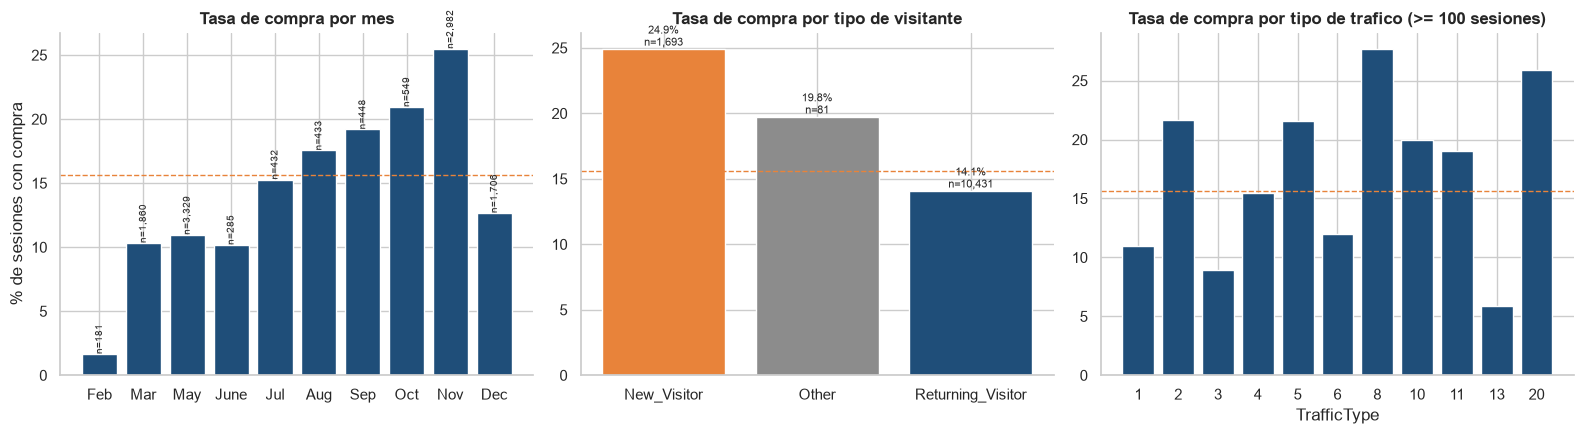

Tasa global de compra (linea naranja): 15.6%
Fin de semana vs semana: {False: 0.151, True: 0.175}


In [12]:
base = df['Revenue'].mean()
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

mes = df.groupby('Month')['Revenue'].agg(['mean', 'size']).reindex(orden_mes)
axs[0].bar(mes.index, mes['mean'] * 100, color=AZUL)
for i, (m, n) in enumerate(zip(mes['mean'], mes['size'])):
    axs[0].text(i, m * 100, f'n={n:,}', ha='center', va='bottom', fontsize=7, rotation=90)
axs[0].set_title('Tasa de compra por mes'); axs[0].set_ylabel('% de sesiones con compra')

vis = df.groupby('VisitorType')['Revenue'].agg(['mean', 'size'])
axs[1].bar(vis.index, vis['mean'] * 100, color=[NARANJA, GRIS, AZUL])
for i, (m, n) in enumerate(zip(vis['mean'], vis['size'])):
    axs[1].text(i, m * 100, f'{m:.1%}\nn={n:,}', ha='center', va='bottom', fontsize=8)
axs[1].set_title('Tasa de compra por tipo de visitante')

tr = df.groupby('TrafficType')['Revenue'].agg(['mean', 'size'])
tr = tr[tr['size'] >= 100]
axs[2].bar(tr.index.astype(str), tr['mean'] * 100, color=AZUL)
axs[2].set_title('Tasa de compra por tipo de trafico (>= 100 sesiones)'); axs[2].set_xlabel('TrafficType')
for a in axs: a.axhline(base * 100, color=NARANJA, ls='--', lw=1)
plt.tight_layout()
plt.savefig(FIG / '01_tasa_compra_categorias.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Tasa global de compra (linea naranja): {base:.1%}')
print('Fin de semana vs semana:', df.groupby('Weekend')['Revenue'].mean().round(3).to_dict())

**Lo que muestra la tasa de compra por categoría**
- **Estacionalidad clara:** la tasa va de **1,7 % en febrero** a **25,5 % en noviembre** (octubre 20,9 %, septiembre 19,2 %). Diciembre baja a 12,7 %. El mes es una variable relevante (se confirmará en la importancia del modelo).
- **Los visitantes nuevos compran más** (24,9 %, n = 1.693) **que los recurrentes** (14,1 %, n = 10.431): contraintuitivo, pero plausible si los nuevos llegan por una campaña con intención de compra y los recurrentes "miran" con más frecuencia.
- **Fin de semana:** 17,5 % contra 15,1 % entre semana, una diferencia pequeña.
- **Tipo de tráfico:** hay fuentes con tasa alta (`TrafficType` 8: 27,7 %; 20: 25,9 %; 2: 21,7 %) y otras con tasa baja (13: 5,9 %; 3: 8,9 %), lo que sugiere que **la calidad del tráfico importa más que su volumen**.

### 6.2 Variables numéricas según el resultado
Se compara la distribución de cada variable entre sesiones con y sin compra, y se mide el **tamaño del efecto** (correlación biserial por rangos derivada de Mann-Whitney, de −1 a 1), porque con miles de sesiones casi cualquier diferencia es "significativa".

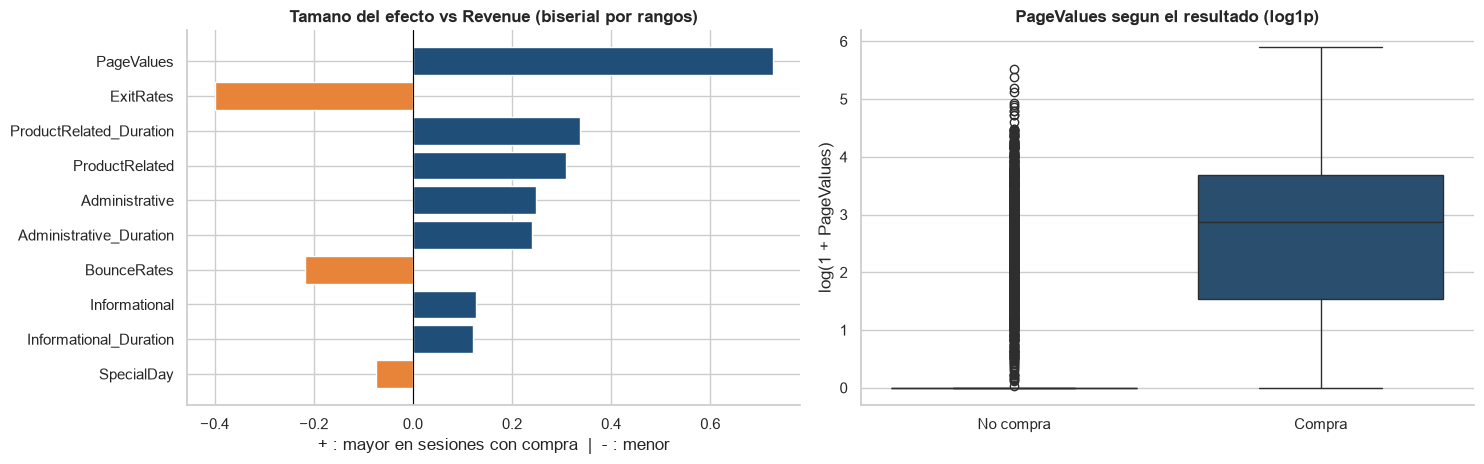

,mean,size
PageValues = 0,0.039,9475
PageValues > 0,0.563,2730


In [13]:
from scipy import stats

def biserial_rangos(x, y):
    u = stats.mannwhitneyu(x, y, alternative='two-sided').statistic
    return 2 * u / (len(x) * len(y)) - 1

efectos = {c: biserial_rangos(df.loc[df['Revenue'], c], df.loc[~df['Revenue'], c]) for c in NUM}
efectos = pd.Series(efectos).sort_values(key=abs, ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
axs[0].barh(efectos.index[::-1], efectos.values[::-1], color=[AZUL if v > 0 else NARANJA for v in efectos.values[::-1]])
axs[0].axvline(0, color='black', lw=.8)
axs[0].set_title('Tamano del efecto vs Revenue (biserial por rangos)')
axs[0].set_xlabel('+ : mayor en sesiones con compra  |  - : menor')

sns.boxplot(data=df.assign(compra=df['Revenue'].map({True: 'Compra', False: 'No compra'}), pv=np.log1p(df['PageValues'])),
            x='compra', y='pv', hue='compra', palette=[GRIS, AZUL], legend=False, ax=axs[1])
axs[1].set_title('PageValues segun el resultado (log1p)'); axs[1].set_xlabel(''); axs[1].set_ylabel('log(1 + PageValues)')
plt.tight_layout()
plt.savefig(FIG / '01_efecto_vs_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

pv = df.groupby(df['PageValues'] > 0)['Revenue'].agg(['mean', 'size'])
pv.index = ['PageValues = 0', 'PageValues > 0']
pv

**Lo que muestra el tamaño del efecto (biserial por rangos)**
- **`PageValues` domina de lejos** (r = 0,73). El resto está lejos: `ExitRates` (−0,40), `ProductRelated_Duration` (0,34), `ProductRelated` (0,31), `Administrative` (0,25), `BounceRates` (−0,22).
- Compran más quienes **navegan más páginas y por más tiempo** y quienes tienen **menos tasa de salida y de rebote**: la dirección de todos los signos tiene sentido de negocio.
- `SpecialDay` tiene efecto **ligeramente negativo** (−0,07): estar cerca de una fecha especial **no** aumenta la tasa de compra en esta muestra, contrario a lo que supondría la documentación del dataset.
- **Señal de alerta:** cuando `PageValues > 0`, el **56,3 %** de las sesiones compra; cuando es 0, solo el **3,9 %**. Una sola variable separa casi todo, lo cual huele a **fuga de información** (ver sección 3). Se estudiará con una ablación en el notebook 03.

### 6.3 Correlaciones y multicolinealidad
Se usa **Spearman** (basada en rangos) por la asimetría de las variables.

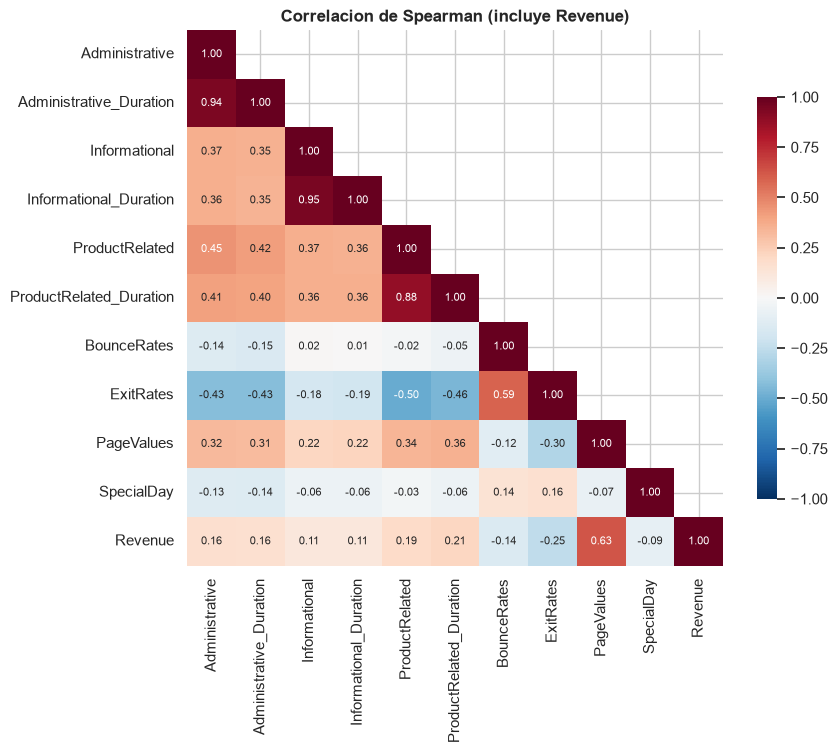

,var1,var2,rho
35,Informational_Duration,Informational,0.951
11,Administrative_Duration,Administrative,0.939
59,ProductRelated_Duration,ProductRelated,0.879
118,Revenue,PageValues,0.626


In [14]:
corr = df[NUM + ['Revenue']].astype(float).corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            annot_kws={'size': 8}, cbar_kws={'shrink': .75}, ax=ax)
ax.set_title('Correlacion de Spearman (incluye Revenue)')
plt.tight_layout()
plt.savefig(FIG / '01_correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()

pares = corr.where(~mask).stack().reset_index()
pares.columns = ['var1', 'var2', 'rho']
pares = pares[pares['var1'] != pares['var2']]
pares.loc[pares['rho'].abs() >= .6].sort_values('rho', key=abs, ascending=False)

**Lo que muestra la correlación**
- Cada **conteo de páginas está casi duplicado por su duración**: `Informational`–`Informational_Duration` (ρ = 0,95), `Administrative`–`Administrative_Duration` (0,94), `ProductRelated`–`ProductRelated_Duration` (0,88). Es **multicolinealidad** esperable: más páginas implican más tiempo.
- `BounceRates` y `ExitRates` están correlacionadas (ρ de Spearman = 0,59; de Pearson 0,91): miden cosas parecidas.
- `PageValues` es la única variable con correlación alta con `Revenue` (ρ = 0,63).
- Consecuencia: los modelos lineales pueden sufrir inestabilidad por colinealidad (se medirá con el VIF en el notebook 02); los de árboles no.

## 7. Hallazgos del EDA y decisiones para el modelado


| # | Hallazgo del EDA | Decisión |
|---|---|---|
| 1 | Desbalance 84,4 % / 15,6 % | Estratificar; métricas PR-AUC, Recall, Precision, F1; pesos de clase y umbral |
| 2 | 125 duplicados (todos sin compra) | Eliminarlos antes de dividir |
| 3 | Variables numéricas muy asimétricas y con muchos ceros | `log(1 + x)` + estandarizar |
| 4 | `Month`, `VisitorType`, `TrafficType` relacionados con la compra | One-hot de las nominales; no tratarlas como números |
| 5 | Conteos y duraciones casi redundantes (ρ ≈ 0,9) | Medir VIF; comparar modelos lineales y de árboles |
| 6 | **`PageValues` separa casi todo y se calcula con información del resultado** | **Ablación**: modelar con y sin ella; excluirla del agrupamiento |
| 7 | Ninguna variable tiene faltantes ni cardinalidad alta | No imputar; one-hot directo |